# GRASP for the CVRP and the CVRPTW

**CesiCDP, ADEME call for expressions of interest, delivery route optimization.**
Owner of this notebook: **Farida** (GRASP, experiments). Team: Pablo (model, exact method, Tabu
Search), Dag (shared base, Simulated Annealing), Farida (GRASP, experimental study, deck).

## 1. Introduction

### The problem in one paragraph
A depot sends identical trucks of capacity $Q$ to serve $n$ customers. Customer $i$ has a
demand $q_i$, a service duration $s_i$ and a time window $[e_i, l_i]$: service may not start
after $l_i$, and a truck that arrives before $e_i$ **waits on site**. Every customer is served
exactly once, every route starts and ends at the depot inside the depot window $[e_0, l_0]$,
and at most $K$ trucks are used. We minimize the **total distance** $\sum_k \sum_{(i,j)\in
\text{route } k} d_{ij}$. This is the CVRPTW (Level A of the brief); without time windows it is
the CVRP (Level B). Both are NP-hard: the CVRP contains the TSP as the special case
$K = 1, Q = \infty$ (see notebook 01 for the reduction).

### Why a metaheuristic, and why GRASP
Exact methods (notebook 01, Pablo) stop scaling after a few dozen customers. GRASP (Greedy
Randomized Adaptive Search Procedure, Feo and Resende, 1995) is a **multi-start** method: each
iteration builds a solution with a *randomized* greedy heuristic, then improves it with a
local search, and the best feasible solution over all iterations is kept. The randomization
(parameter $\alpha$) controls the trade-off between the quality of each start and the
diversity of the starts.

### What this notebook shows
1. How the GRASP is built on the team's shared `Instance` and `Solution` classes
   (`src/cvrp/grasp.py`), so its solutions are checked by the same evaluator as the others.
2. How it performs on Solomon benchmark instances of the three families **C** (clustered),
   **R** (random) and **RC** (mixed), against the best known values, with 10 seeds.
3. How its parameters were tuned on a **separate tuning set**, and what each parameter does.
4. How it scales with the instance size, up to 2 000 customers.

> Reading guide: every table or figure is followed by one sentence saying what it means.

## 2. Imports and configuration

Everything that an experiment depends on is set in the next cell: dataset lists, seeds,
GRASP parameters and whether to recompute results or reload them from `results/`.
Change a list or a value here and rerun the notebook.

In [1]:
import sys
import time
from pathlib import Path

# Find the repository root (the folder that contains src/cvrp), wherever the kernel starts.
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "cvrp").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))  # works without `pip install -e .`

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from cvrp import Instance, Solution
from cvrp.utils import distance_matrix, gap_percent
from cvrp.viz import plot_routes
from cvrp import grasp as G
from cvrp.grasp import GRASPParams, grasp

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
# Validated categorical palette (colorblind-checked): one fixed color per family / variant.
FAMILY_COLOR = {"C": "#2a78d6", "R": "#eb6834", "RC": "#1baf7a"}
VARIANT_COLOR = {"GRASP": "#2a78d6", "GRASP-ILS": "#eb6834"}

DATA = ROOT / "data"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
print("repository root:", ROOT)

repository root: /home/claude/repo/cesi-cvrp-metaheuristics


In [2]:
# ---- Test instances: at least three per Solomon family (edit freely) -------------------
DATASETS = [
    "C101", "C102", "C105", "C108",
    "R101", "R102", "R103", "R105",
    "RC101", "RC102", "RC105", "RC106", "RC108",
]
# ---- Tuning instances: disjoint from the test set (team rule: tuning never sees test) --
TUNING_SET = ["C104", "C109", "R112", "RC104"]

SEEDS = list(range(1, 11))          # 10 seeds per (instance, variant), as in the study plan
TUNING_SEEDS = [1, 2, 3]

# ---- The two GRASP variants compared in this notebook (values from Section 6) ---------
VARIANTS = {
    # Plain GRASP: construction + local search, 100 independent starts.
    "GRASP": GRASPParams(alpha=0.1, iterations=100, improvement="first", enhanced=True,
                         construction="regret"),
    # GRASP-ILS: 10 starts, each intensified by 90 kick-and-descend rounds.
    "GRASP-ILS": GRASPParams(alpha=0.1, iterations=10, improvement="first", enhanced=True,
                             construction="regret", perturb_kicks=90),
}

DISTANCE_CONVENTION = "floor1"   # see Section 3: the convention of the reference values
RERUN = False   # False: reload the saved CSVs in results/ (fast, for the demo).
                # True: recompute every experiment (about 25 min on a 2-core laptop).

## 3. Dataset loading

### Instances
Solomon instances (`data/solomon/<NAME>.txt`) are read with the team loader
`Instance.from_vrplib(..., instance_format="solomon")`; VRPLIB X instances
(`data/cvrplib/X/<NAME>.vrp`) with the default format. Files are not committed (see
`data/README.md`), so a missing file is reported and skipped, never fatal.

### Reference values and the distance convention
A gap is only meaningful if our cost and the reference cost are computed the same way. Two
traps exist for Solomon:

| Trap | What it changes | What we do |
|---|---|---|
| **Objective.** The SINTEF table is *hierarchical* (fewest vehicles first, then distance). Exact methods minimize distance only. | R101: 1650.80 with 19 trucks (hierarchical) vs **1637.7** with 20 trucks (distance). | Our objective is distance, so we compare with the **distance-optimal** values (Kohl et al. 1999; Kallehauge et al.; table maintained by Spoorendonk, DIKU). |
| **Rounding.** Those optimal values use distances **truncated to one decimal**. | C101 reference solution: 828.94 in double precision, 827.3 truncated. | Our distance matrix uses the same truncation (`distance_matrix(..., "floor1")`), and the cell below *proves* it reproduces 827.3 on the published C101 solution. |

For the X instance (CVRP) the reference is the best known solution file of CVRPLIB, with
distances rounded to the nearest integer (the CVRPLIB convention, already applied by the
team loader).

In [3]:
# Distance-optimal values (truncated one-decimal distances). NV = trucks in that solution.
# Source: Spoorendonk (DIKU) tables of optimal Solomon solutions, from Kohl et al. (1999),
# Kallehauge, Larsen and Madsen, Chabrier, and others. C1 values: 827.3 except C104 (822.9).
REFERENCES = {
    "C101": (827.3, 10), "C102": (827.3, 10), "C104": (822.9, 10), "C105": (827.3, 10),
    "C108": (827.3, 10), "C109": (827.3, 10),
    "R101": (1637.7, 20), "R102": (1466.6, 18), "R103": (1208.7, 14), "R105": (1355.3, 15),
    "R112": (948.6, 10),
    "RC101": (1619.8, 15), "RC102": (1457.4, 14), "RC104": (1132.3, 10), "RC105": (1513.7, 15),
    "RC106": (1372.7, 13), "RC108": (1114.2, 11),
}


def family(name: str) -> str:
    # Solomon family from the instance name: C, R or RC.
    return "RC" if name.upper().startswith("RC") else name[0].upper()


def load_instance(name: str, convention: str = DISTANCE_CONVENTION) -> Instance:
    # Load a Solomon (.txt) or VRPLIB X (.vrp) instance with the team loader.
    if name.startswith("X-"):
        inst = Instance.from_vrplib(DATA / "cvrplib" / "X" / f"{name}.vrp")
        # CVRPLIB "-k25" is the MINIMUM number of trucks, not a fleet limit: the published
        # best known solution of X-n101-k25 uses 26 routes. So the fleet is left unbounded.
        inst.num_vehicles = None
        return inst
    path = DATA / "solomon" / f"{name}.txt"
    if not path.exists():
        raise FileNotFoundError(f"{path.relative_to(ROOT)} not found (see data/README.md)")
    inst = Instance.from_vrplib(path, instance_format="solomon")
    inst.dist = distance_matrix(inst.coords, rounding=convention)  # objective = travel time
    inst.best_known = REFERENCES.get(name, (None, None))[0]
    return inst


def load_reference_solution(name: str) -> Solution | None:
    # Published reference solution (.sol next to the instance), when the file is available.
    import vrplib
    for path in (DATA / "solomon" / f"{name}.sol", DATA / "cvrplib" / "X" / f"BKS-{name}.txt"):
        if path.exists():
            return Solution([list(r) for r in vrplib.read_solution(str(path))["routes"]])
    return None


available = [n for n in DATASETS + TUNING_SET if (DATA / "solomon" / f"{n}.txt").exists()]
missing = [n for n in DATASETS + TUNING_SET if n not in available]
print("available:", available)
print("missing (download them into data/solomon/ to include them):", missing)

available: ['C101', 'C105', 'C108', 'R101', 'R102', 'R103', 'RC105', 'RC106', 'RC108', 'C104', 'C109', 'R112', 'RC104']
missing (download them into data/solomon/ to include them): ['C102', 'R105', 'RC101', 'RC102']


**Convention check.** Evaluate the published C101 solution with our evaluator:

In [4]:
inst = load_instance("C101")
ref_sol = load_reference_solution("C101")
exact = Instance.from_vrplib(DATA / "solomon" / "C101.txt", instance_format="solomon")
print(f"C101 reference solution, {len(ref_sol)} routes")
print(f"  cost, double precision distances : {ref_sol.cost(exact):.2f}")
print(f"  cost, truncated one-decimal      : {ref_sol.cost(inst):.2f}   (reference: {inst.best_known})")
print(f"  violations in the shared evaluator: {ref_sol.violations(inst) or 'none'}")

C101 reference solution, 10 routes
  cost, double precision distances : 828.94
  cost, truncated one-decimal      : 827.30   (reference: 827.3)
  violations in the shared evaluator: none


The truncated convention reproduces the reference value exactly, and the team evaluator
accepts the published solution as feasible, so the gaps below compare like with like.

In [5]:
rows = []
for name in available:
    i = load_instance(name)
    width = i.due_times[1:] - i.ready_times[1:]
    rows.append({"Dataset": name, "Family": family(name), "Set": "test" if name in DATASETS else "tuning",
                 "n": i.n_customers, "Q": i.capacity, "K": i.num_vehicles,
                 "Mean window width": width.mean(), "Horizon l0": i.due_times[0],
                 "Reference": REFERENCES[name][0], "Ref. trucks": REFERENCES[name][1]})
instances_df = pd.DataFrame(rows)
instances_df

,Dataset,Family,Set,n,Q,K,Mean window width,Horizon l0,Reference,Ref. trucks
0,C101,C,test,100,200.0,25,60.76,1236.0,827.3,10
1,C105,C,test,100,200.0,25,121.61,1236.0,827.3,10
2,C108,C,test,100,200.0,25,243.28,1236.0,827.3,10
3,R101,R,test,100,200.0,25,10.00,230.0,1637.7,20
4,R102,R,test,100,200.0,25,57.39,230.0,1466.6,18
5,R103,R,test,100,200.0,25,102.99,230.0,1208.7,14
6,RC105,RC,test,100,200.0,25,54.33,240.0,1513.7,15
7,RC106,RC,test,100,200.0,25,60.00,240.0,1372.7,13
8,RC108,RC,test,100,200.0,25,112.33,240.0,1114.2,11
9,C104,C,tuning,100,200.0,25,852.94,1236.0,822.9,10


Within a family the customers are at the same places; what changes is the window width.
C1 and R1 have short horizons and tight windows (many trucks), the tuning set contains the
wide-window members (C104, R112, RC104), which are harder for a local search because many
more sequences are feasible.

## 4. GRASP implementation

The code is in `src/cvrp/grasp.py`. It reads the shared `Instance`, returns a shared `Solution`
and never modifies the teammates' modules. Pseudocode:

```
GRASP(instance, alpha, iterations):
    best = None
    repeat iterations times:
        S = RandomizedGreedyConstruction(alpha)        # Section 4.1
        if S uses more than K trucks: EliminateRoutes(S)
        S = LocalSearch(S)                             # Section 4.2 (VND)
        repeat perturb_kicks times:                    # Section 4.3, optional (GRASP-ILS)
            S' = LocalSearch(Kick(S));  if cost(S') < cost(S): S = S'
        if S is feasible (shared evaluator) and cost(S) < cost(best): best = S
    return best
```

### 4.1 Randomized adaptive construction
*Parallel insertion.* For every unrouted customer $u$ the code keeps its cheapest feasible
insertion in every open route, $c(u) = \min_{(a,b)} \; d_{au} + d_{ub} - d_{ab}$. After an
insertion only the modified route is re-evaluated (this is the **adaptive** part of GRASP:
the greedy values change with the partial solution).

*Score.* With `construction="regret"` the score of $u$ is $c_1(u) - (c_2(u) - c_1(u))$, where
$c_1, c_2$ are its best and second best route. A customer with a large **regret** has only one
good route left, so it is served before that route fills up.

*Restricted candidate list.* $\text{RCL} = \{u : \text{score}(u) \le s_{\min} + \alpha\,(s_{\max} - s_{\min})\}$;
one customer is drawn uniformly from the RCL. $\alpha = 0$ is the pure greedy heuristic
(always the same solution), $\alpha = 1$ is a random insertion order.

*New routes.* When no customer fits anywhere, a route is opened with a seed customer drawn
among the farthest from the depot or the earliest due ones.

### 4.2 Local search: granular Variable Neighborhood Descent

| Neighborhood | Move | Routes |
|---|---|---|
| Relocate | move one customer next to one of its neighbors | intra and inter |
| Swap | exchange two customers | inter |
| 2-opt* | exchange the tails of two routes (creates edge $(u, v)$) | inter |
| Or-opt | move a chain of 2 or 3 consecutive customers | inter |
| Cross-exchange (*enhanced*) | exchange two segments of up to 2 customers | inter |
| 2-opt | reverse a segment | intra |

The neighborhoods are tried in this order; after any improvement the descent restarts from
the first one, and it stops when none improves (a local optimum for all of them).
`improvement="first"` applies the first improving move found; `"best"` scans the whole
neighborhood and applies the best one.

**Granularity.** A move is only tried between a customer and its 20 nearest customers
(Toth and Vigo, 2003): long edges almost never appear in good solutions, so the neighborhood
shrinks from $O(n^2)$ to $O(20\,n)$ with little loss.

**O(1) time-window check.** Each route stores, for each position $k$, the service start
$A_k$ (forward pass, with waiting) and the latest feasible start $Z_k$ (backward pass,
Savelsbergh 1992):

$$A_k = \max\big(e_{p_k},\; A_{k-1} + s_{p_{k-1}} + d_{p_{k-1} p_k}\big), \qquad
Z_k = \min\big(l_{p_k},\; Z_{k+1} - s_{p_k} - d_{p_k p_{k+1}}\big).$$

Inserting customer $u$ between positions $k$ and $k+1$ is feasible if and only if
$t_u = \max(e_u, A_k + s_{p_k} + d_{p_k u}) \le l_u$ and $t_u + s_u + d_{u\,p_{k+1}} \le Z_{k+1}$.
The same idea checks swap, Or-opt, cross-exchange and 2-opt* without re-simulating routes,
which is what makes a pure Python local search fast enough. The capacity check uses cached
prefix loads the same way.

**Safety net.** These caches only speed up the search. Every solution kept by the GRASP is
re-checked by the shared `Solution.violations` evaluator.

### 4.3 Optional intensification: GRASP-ILS
Section 6 shows that for a fixed time budget, spending effort on improving each start beats
doing more starts. With `perturb_kicks > 0`, each GRASP iteration becomes a short iterated
local search: remove a cluster of 10 to 20 % of the customers (a seed and its nearest
neighbors), reinsert them by cheapest feasible insertion, descend again, and keep the result
only if it is better. This is a documented GRASP hybridization (GRASP + ILS, Resende and
Ribeiro, 2010). Both variants are reported separately so the plain GRASP stays visible.

### 4.4 Step by step on C105
The next cell runs the phases by hand: one construction, then one local search.

construction : cost    965.2, 10 routes, feasible True, 9 ms
local search : cost    827.3, 10 routes, feasible True, 13 improving moves, 7 ms


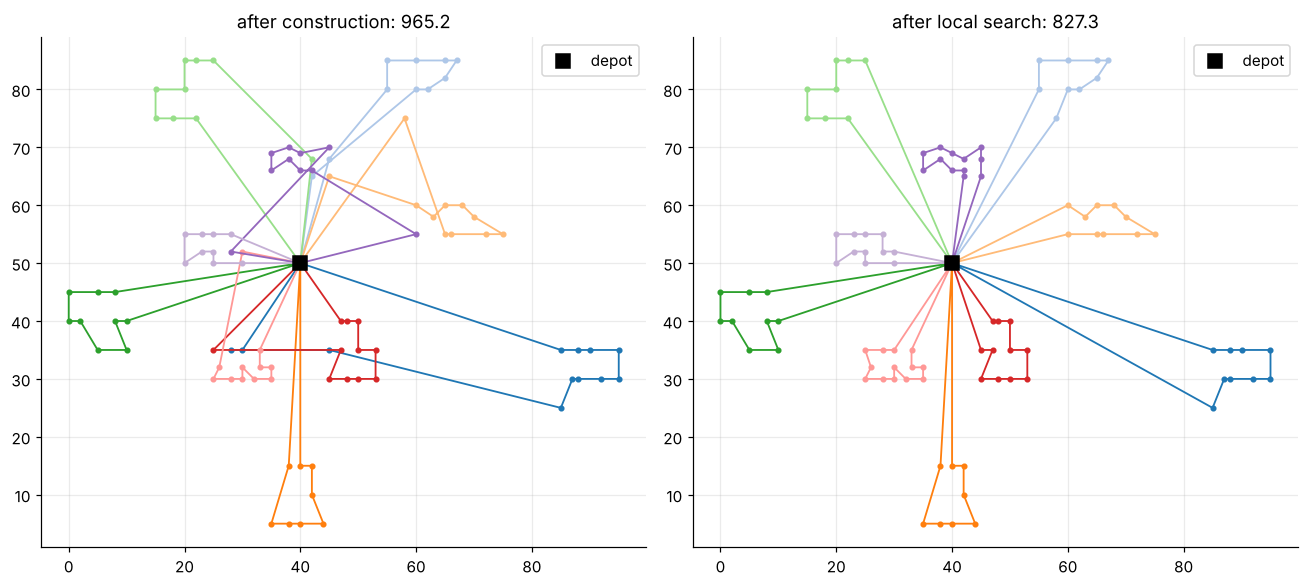

In [6]:
import random

inst = load_instance("C105")
params = GRASPParams(alpha=0.1)
model = G._Model(inst, params.n_neighbors)        # instance copied into Python lists
rng = random.Random(42)

t = time.perf_counter()
state = G.construct(model, rng, params.alpha, params.construction, params.tw_weight)
built = state.to_solution()
t_build = time.perf_counter() - t
print(f"construction : cost {built.cost(inst):8.1f}, {len(built)} routes, "
      f"feasible {built.is_feasible(inst)}, {t_build*1000:.0f} ms")

t = time.perf_counter()
moves = G._LocalSearch(model, state, rng, params).run()
improved = state.to_solution()
print(f"local search : cost {improved.cost(inst):8.1f}, {len(improved)} routes, "
      f"feasible {improved.is_feasible(inst)}, {moves} improving moves, "
      f"{(time.perf_counter()-t)*1000:.0f} ms")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
plot_routes(inst, built, ax=axes[0], title=f"after construction: {built.cost(inst):.1f}")
plot_routes(inst, improved, ax=axes[1], title=f"after local search: {improved.cost(inst):.1f}")
plt.tight_layout(); plt.show()

The construction already respects capacity and every window; the local search then removes
the crossings and long edges between clusters. Both phases take milliseconds, which leaves
room for many starts.

## 5. Single-instance testing

Quick debugging entry point: pick an instance and a variant, run it, look at the solution and
the convergence of the multi-start.

C105 with GRASP, seed 42
  feasible      : True   violations: none
  routes        : 10 (reference solution: 10)
  total distance: 827.3   reference: 827.3   gap: 0.00 %
  runtime       : 1.82 s for 100 iterations


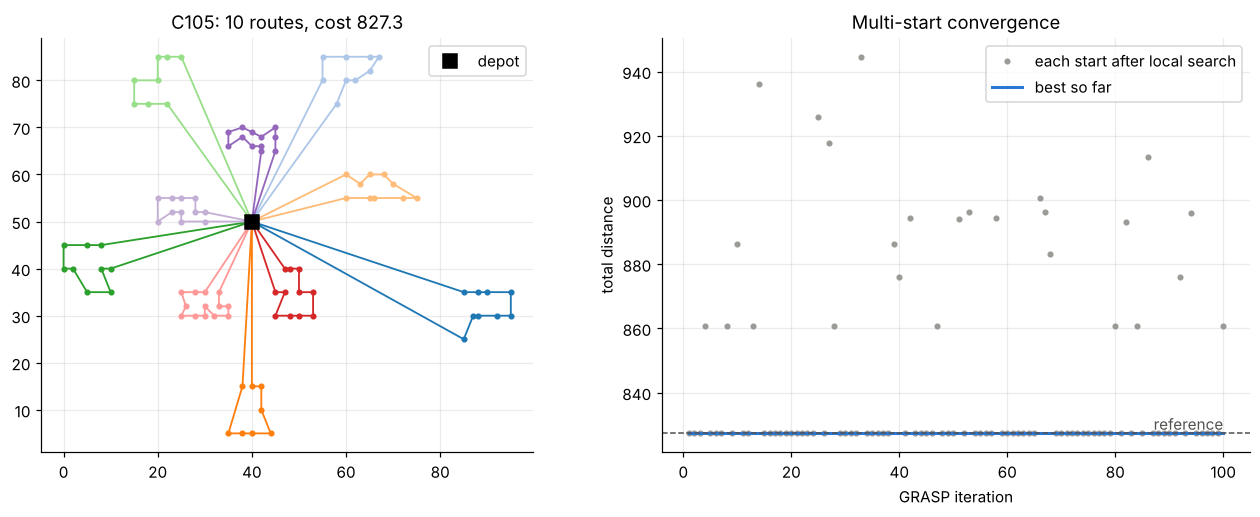

In [7]:
INSTANCE = "C105"          # any available instance
VARIANT = "GRASP"          # "GRASP" or "GRASP-ILS"
SEED = 42

inst = load_instance(INSTANCE)
res = grasp(inst, VARIANTS[VARIANT], seed=SEED)
sol = res.best
print(f"{INSTANCE} with {VARIANT}, seed {SEED}")
print(f"  feasible      : {sol.is_feasible(inst)}   violations: {sol.violations(inst) or 'none'}")
print(f"  routes        : {len(sol)} (reference solution: {REFERENCES[INSTANCE][1]})")
print(f"  total distance: {res.cost:.1f}   reference: {inst.best_known}   "
      f"gap: {gap_percent(res.cost, inst.best_known):.2f} %")
print(f"  runtime       : {res.runtime:.2f} s for {res.iterations} iterations")

h = pd.DataFrame(res.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
plot_routes(inst, sol, ax=axes[0])
axes[1].plot(h.iteration, h.after_ls, "o", ms=3, color="#9a9a96", label="each start after local search")
axes[1].plot(h.iteration, h.best, "-", lw=2, color=VARIANT_COLOR["GRASP"], label="best so far")
axes[1].axhline(inst.best_known, ls="--", lw=1, color="#52514e")
axes[1].annotate("reference", (h.iteration.max(), inst.best_known), ha="right", va="bottom",
                 color="#52514e")
axes[1].set_xlabel("GRASP iteration"); axes[1].set_ylabel("total distance")
axes[1].set_title("Multi-start convergence"); axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

Each grey dot is one independent start after its local search: their spread is the diversity
produced by $\alpha$, and the best-so-far curve shows how many starts were needed.

### Experiment runner
One function runs one (instance, configuration, seed) and returns one row with every metric
of the study plan. A failure on one instance (missing file, crash) is recorded as a row with
an `error` and the campaign continues.

In [8]:
def run_one(name: str, params: GRASPParams, seed: int, variant: str = "") -> dict:
    # Run the GRASP once and return one result row (never raises).
    row = {"Dataset": name, "Family": family(name) if not name.startswith("X-") else "X",
           "Variant": variant, "Alpha": params.alpha, "Iterations": params.iterations,
           "Kicks": params.perturb_kicks, "Seed": seed, "Improvement": params.improvement,
           "Enhanced": params.enhanced, "Construction": params.construction}
    try:
        inst = load_instance(name)
        res = grasp(inst, params, seed=seed)
        sol = res.best
        ref = inst.best_known if inst.best_known is not None else REFERENCES.get(name, (None,))[0]
        feasible = sol is not None and sol.is_feasible(inst)   # shared evaluator
        row.update({
            "Feasible": feasible,
            "Routes": len(sol) if sol else np.nan,
            "Cost": res.cost,
            "Reference": ref,
            "Gap (%)": gap_percent(res.cost, ref) if (ref and feasible) else np.nan,
            "Runtime (s)": res.runtime,
            "error": "",
        })
    except Exception as exc:  # noqa: BLE001 - one bad instance must not stop the campaign
        row.update({"Feasible": False, "Routes": np.nan, "Cost": np.nan, "Reference": np.nan,
                    "Gap (%)": np.nan, "Runtime (s)": np.nan, "error": f"{type(exc).__name__}: {exc}"})
    return row


def run_experiments(datasets, configs: dict, seeds, csv_name: str) -> pd.DataFrame:
    # Run every (dataset, config, seed), print progress, save the CSV and return it.
    path = RESULTS / csv_name
    if not RERUN and path.exists():
        print(f"reloaded {path.relative_to(ROOT)}")
        return pd.read_csv(path)
    rows, t0 = [], time.perf_counter()
    for name in datasets:
        try:
            load_instance(name)
        except Exception as exc:  # noqa: BLE001 - report and move on to the next instance
            print(f"  {name:6s} SKIPPED ({type(exc).__name__}: {exc})")
            rows.append({"Dataset": name, "Family": family(name), "Feasible": False,
                         "error": f"{type(exc).__name__}: {exc}"})
            continue
        for label, params in configs.items():
            for seed in seeds:
                rows.append(run_one(name, params, seed, label))
        ok = [r for r in rows if r["Dataset"] == name and not r["error"]]
        if ok:
            print(f"  {name:6s} done, mean gap {np.nanmean([r['Gap (%)'] for r in ok]):5.2f} %, "
                  f"elapsed {time.perf_counter()-t0:6.0f} s")
    df = pd.DataFrame(rows)
    df.to_csv(path, index=False)
    print(f"saved {len(df)} rows to {path.relative_to(ROOT)}")
    return df

## 6. Parameter tuning (on the tuning set only)

Parameters are chosen on `TUNING_SET` (C104, C109, R112, RC104), never on the test instances,
so the test results of Section 7 are not optimistic. Three seeds per configuration,
30 iterations, plain GRASP. *(This section comes before the campaign because the campaign
uses its conclusions.)*

### 6.1 Greediness $\alpha$ and first vs best improvement

In [9]:
grid = {f"a={a} {im}": GRASPParams(alpha=a, iterations=30, improvement=im)
        for a in (0.1, 0.3, 0.5) for im in ("first", "best")}
tune1 = run_experiments(TUNING_SET, grid, TUNING_SEEDS, "grasp_tuning_alpha.csv")
summary1 = (tune1.groupby(["Alpha", "Improvement"])
            .agg(mean_gap=("Gap (%)", "mean"), std_gap=("Gap (%)", "std"),
                 runtime=("Runtime (s)", "mean"), feasible=("Feasible", "mean"))
            .reset_index())
summary1

reloaded results/grasp_tuning_alpha.csv


,Alpha,Improvement,mean_gap,std_gap,runtime,feasible
0,0.1,best,3.48,2.79,1.47,1.0
1,0.1,first,3.89,2.77,0.77,1.0
2,0.3,best,5.16,3.33,2.03,1.0
3,0.3,first,4.88,2.68,0.91,1.0
4,0.5,best,5.29,4.01,2.83,1.0
5,0.5,first,4.72,3.02,0.98,1.0


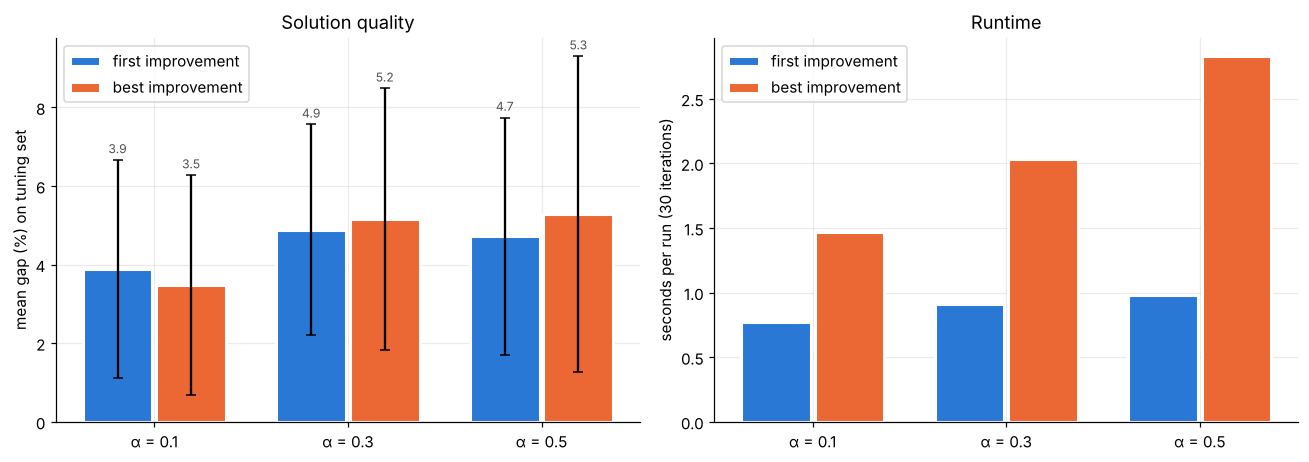

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
x = np.arange(3)
for k, (im, color) in enumerate((("first", "#2a78d6"), ("best", "#eb6834"))):
    s = summary1[summary1.Improvement == im].sort_values("Alpha")
    axes[0].bar(x + (k - 0.5) * 0.38, s.mean_gap, 0.36, yerr=s.std_gap, capsize=3,
                color=color, label=f"{im} improvement", edgecolor="white", linewidth=2)
    axes[1].bar(x + (k - 0.5) * 0.38, s.runtime, 0.36, color=color, label=f"{im} improvement",
                edgecolor="white", linewidth=2)
    for xi, v, sd in zip(x + (k - 0.5) * 0.38, s.mean_gap, s.std_gap.fillna(0)):
        axes[0].text(xi, v + sd + 0.1, f"{v:.1f}", ha="center", va="bottom", fontsize=8, color="#52514e")
for ax in axes:
    ax.set_xticks(x, ["α = 0.1", "α = 0.3", "α = 0.5"]); ax.legend()
axes[0].set_ylabel("mean gap (%) on tuning set"); axes[0].set_title("Solution quality")
axes[1].set_ylabel("seconds per run (30 iterations)"); axes[1].set_title("Runtime")
plt.tight_layout(); plt.show()

A small $\alpha$ (more greedy starts) gives the best gaps: with tight windows a random
insertion order wastes trucks that the local search cannot recover. First improvement is
within a few tenths of a point of best improvement and roughly twice as fast, because best improvement scans
the whole neighborhood for every single move. **Kept: $\alpha = 0.1$, first improvement.**

### 6.2 Construction rule, enhanced neighborhoods, time-window weight

In [11]:
grid2 = {
    "regret + enhanced": GRASPParams(iterations=30, construction="regret", enhanced=True),
    "regret, basic ops": GRASPParams(iterations=30, construction="regret", enhanced=False),
    "cheapest + enhanced": GRASPParams(iterations=30, construction="cheapest", enhanced=True),
    "cheapest, basic ops": GRASPParams(iterations=30, construction="cheapest", enhanced=False),
    "regret + enhanced + TW push 0.5": GRASPParams(iterations=30, tw_weight=0.5),
}
tune2 = run_experiments(TUNING_SET, grid2, TUNING_SEEDS, "grasp_tuning_components.csv")
(tune2.pivot_table(index="Variant", columns="Dataset", values="Gap (%)", aggfunc="mean")
      .assign(mean=lambda d: d.mean(axis=1),
              runtime=tune2.groupby("Variant")["Runtime (s)"].mean())
      .sort_values("mean"))

reloaded results/grasp_tuning_components.csv


Dataset,C104,C109,R112,RC104,mean,runtime
Variant,,,,,,
regret + enhanced,3.96,0.0,6.39,5.22,3.89,0.75
regret + enhanced + TW push 0.5,5.46,0.0,5.16,5.15,3.94,0.81
cheapest + enhanced,3.75,0.0,6.92,5.54,4.05,0.89
"regret, basic ops",5.27,0.0,6.62,4.87,4.19,0.66
"cheapest, basic ops",5.35,0.0,8.12,5.57,4.76,0.76


Regret insertion and the cross-exchange operator each lower the gap; adding the time
push-forward term to the insertion cost (Solomon's I1 idea) does not help once a local search
follows. **Kept: regret construction, enhanced neighborhoods, no time weight.**

### 6.3 More starts or deeper starts? (equal time budget)
Both variants get the same 10 seconds per run.

In [12]:
grid3 = {
    "GRASP (restarts only)": GRASPParams(iterations=10**6, time_limit=10.0),
    "GRASP-ILS (90 kicks per start)": GRASPParams(iterations=10**6, perturb_kicks=90, time_limit=10.0),
}
tune3 = run_experiments(TUNING_SET, grid3, TUNING_SEEDS, "grasp_tuning_budget.csv")
(tune3.groupby(["Variant", "Dataset"])["Gap (%)"].mean().unstack()
      .assign(mean=lambda d: d.mean(axis=1)))

reloaded results/grasp_tuning_budget.csv


Dataset,C104,C109,R112,RC104,mean
Variant,,,,,
GRASP (restarts only),0.97,0.0,5.02,3.62,2.40
GRASP-ILS (90 kicks per start),0.00,0.0,1.73,0.65,0.59


In [13]:
budget_iters = {}
for label, params in grid3.items():
    r = grasp(load_instance("R112"), params, seed=1)
    budget_iters[label] = r.iterations
print("GRASP iterations completed in 10 s on R112:", budget_iters)

GRASP iterations completed in 10 s on R112: {'GRASP (restarts only)': 349, 'GRASP-ILS (90 kicks per start)': 12}


At equal time, the intensified variant is clearly better: once $\alpha$ is small, new starts
mostly land in the same basins, while a kick explores *around* a good solution. This is why
the campaign reports both the plain GRASP (the method as specified) and GRASP-ILS (our
improved version), with 10 starts × 90 kicks.

## 7. Automated multi-dataset experiments

Every instance of `DATASETS` × both variants × 10 seeds. Each row of the result table has
the metrics of the study plan: dataset, family, $\alpha$, iterations, seed, improvement,
enhanced, feasibility (shared evaluator), routes, cost, reference, gap and runtime.
Results are written to `results/grasp_campaign.csv`.

In [14]:
campaign = run_experiments(DATASETS, VARIANTS, SEEDS, "grasp_campaign.csv")
ok = campaign[campaign.error.fillna("") == ""]
print(f"\n{len(ok)} runs, {ok.Feasible.mean():.0%} feasible, "
      f"skipped instances: {sorted(set(campaign.Dataset) - set(ok.Dataset)) or 'none'}")
ok.head(12)

reloaded results/grasp_campaign.csv

180 runs, 100% feasible, skipped instances: ['C102', 'R105', 'RC101', 'RC102']


,Dataset,Family,Variant,Alpha,Iterations,Kicks,Seed,Improvement,Enhanced,Construction,Feasible,Routes,Cost,Reference,Gap (%),Runtime (s),error
0,C101,C,GRASP,0.1,100.0,0.0,1.0,first,True,regret,True,10.0,827.3,827.3,0.0,2.06,NaN
1,C101,C,GRASP,0.1,100.0,0.0,2.0,first,True,regret,True,10.0,827.3,827.3,0.0,1.88,NaN
2,C101,C,GRASP,0.1,100.0,0.0,3.0,first,True,regret,True,10.0,827.3,827.3,0.0,1.87,NaN
3,C101,C,GRASP,0.1,100.0,0.0,4.0,first,True,regret,True,10.0,827.3,827.3,0.0,1.83,NaN
4,C101,C,GRASP,0.1,100.0,0.0,5.0,first,True,regret,True,10.0,827.3,827.3,0.0,1.76,NaN
5,C101,C,GRASP,0.1,100.0,0.0,6.0,first,True,regret,True,10.0,827.3,827.3,0.0,1.82,NaN
6,C101,C,GRASP,0.1,100.0,0.0,7.0,first,True,regret,True,10.0,827.3,827.3,0.0,1.86,NaN
7,C101,C,GRASP,0.1,100.0,0.0,8.0,first,True,regret,True,10.0,827.3,827.3,0.0,1.88,NaN
8,C101,C,GRASP,0.1,100.0,0.0,9.0,first,True,regret,True,10.0,827.3,827.3,0.0,1.77,NaN
9,C101,C,GRASP,0.1,100.0,0.0,10.0,first,True,regret,True,10.0,827.3,827.3,0.0,1.83,NaN


### 7.1 Results per instance (mean over 10 seeds)

In [15]:
per_inst = (ok.groupby(["Variant", "Family", "Dataset"])
              .agg(Reference=("Reference", "first"), Best=("Cost", "min"), Mean=("Cost", "mean"),
                   Gap_best=("Gap (%)", "min"), Gap_mean=("Gap (%)", "mean"),
                   Gap_std=("Gap (%)", "std"), Routes=("Routes", "mean"),
                   Runtime=("Runtime (s)", "mean"), Feasible=("Feasible", "mean"))
              .reset_index())
per_inst["Ref. trucks"] = per_inst.Dataset.map(lambda n: REFERENCES[n][1])
per_inst.round(2)

,Variant,Family,Dataset,Reference,Best,Mean,Gap_best,Gap_mean,Gap_std,Routes,Runtime,Feasible,Ref. trucks
0,GRASP,C,C101,827.3,827.3,827.30,0.00,0.00,0.00,10.0,1.86,1.0,10
1,GRASP,C,C105,827.3,827.3,827.30,0.00,0.00,0.00,10.0,1.72,1.0,10
2,GRASP,C,C108,827.3,827.3,827.30,0.00,0.00,0.00,10.0,1.97,1.0,10
3,GRASP,R,R101,1637.7,1642.4,1648.20,0.29,0.64,0.24,20.0,2.52,1.0,20
4,GRASP,R,R102,1466.6,1473.0,1479.43,0.44,0.87,0.24,18.5,2.64,1.0,18
5,GRASP,R,R103,1208.7,1227.5,1234.00,1.56,2.09,0.37,14.8,2.56,1.0,14
6,GRASP,RC,RC105,1513.7,1532.3,1549.24,1.23,2.35,0.88,15.6,2.67,1.0,15
7,GRASP,RC,RC106,1372.7,1402.4,1422.94,2.16,3.66,1.03,13.6,2.65,1.0,13
8,GRASP,RC,RC108,1114.2,1138.4,1164.40,2.17,4.51,1.05,11.7,2.75,1.0,11
9,GRASP-ILS,C,C101,827.3,827.3,827.30,0.00,0.00,0.00,10.0,4.15,1.0,10


### 7.2 VRPLIB check on a CVRP instance (Level B)

In [16]:
cvrp_ref = load_reference_solution("X-n101-k25")
x_inst = load_instance("X-n101-k25")
x_inst.best_known = cvrp_ref.cost(x_inst)
print(f"X-n101-k25 best known solution: {x_inst.best_known:.0f}, {len(cvrp_ref)} routes, "
      f"violations: {cvrp_ref.violations(x_inst) or 'none'}")
REFERENCES["X-n101-k25"] = (x_inst.best_known, len(cvrp_ref))
x_rows = []
for label, params in VARIANTS.items():
    for seed in SEEDS[:5]:
        r = grasp(x_inst, params, seed=seed)
        x_rows.append({"Variant": label, "Seed": seed, "Feasible": r.best.is_feasible(x_inst),
                       "Routes": len(r.best), "Cost": r.cost,
                       "Gap (%)": gap_percent(r.cost, x_inst.best_known), "Runtime (s)": r.runtime})
x_df = pd.DataFrame(x_rows)
x_df.to_csv(RESULTS / "grasp_cvrp_x.csv", index=False)
x_df.groupby("Variant")[["Feasible", "Routes", "Cost", "Gap (%)", "Runtime (s)"]].agg(["mean", "min"]).round(2)

X-n101-k25 best known solution: 27591, 26 routes, violations: none


Feasible       Routes         Cost          Gap (%)        \
              mean   min   mean min     mean      min    mean   min   
Variant                                                               
GRASP          1.0  True   26.4  26  28296.2  28218.0    2.56  2.27   
GRASP-ILS      1.0  True   26.2  26  27793.6  27686.0    0.73  0.34   

          Runtime (s)        
                 mean   min  
Variant                      
GRASP            1.74  1.70  
GRASP-ILS        7.60  7.56

The same code solves the CVRP without change (the time-window checks are skipped when the
instance has none). Note for the team: the shared loader reads the fleet size from the `-k25`
in the name, but in CVRPLIB `k` is the minimum number of trucks and the published best
solution uses 26 routes, so `load_instance` leaves the fleet unbounded for X instances.

## 8. Results and visualization

### 8.1 Gap by dataset

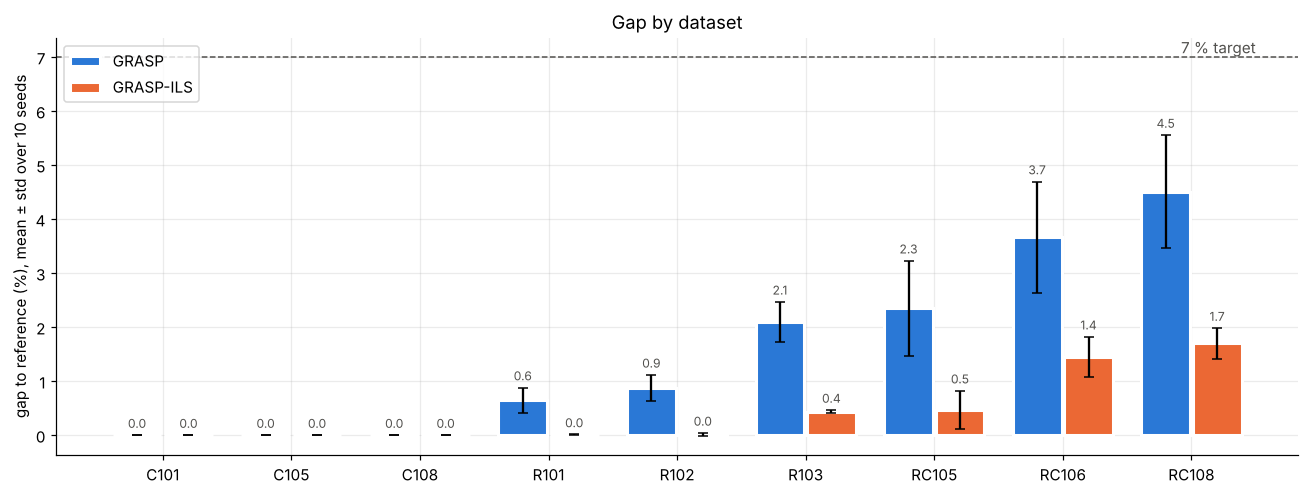

In [17]:
order = [n for n in DATASETS if n in set(ok.Dataset)]
fig, ax = plt.subplots(figsize=(12, 4.6))
x = np.arange(len(order))
for k, (variant, color) in enumerate(VARIANT_COLOR.items()):
    s = per_inst[per_inst.Variant == variant].set_index("Dataset").loc[order]
    xs = x + (k - 0.5) * 0.4
    ax.bar(xs, s.Gap_mean, 0.38, yerr=s.Gap_std, capsize=3, color=color, label=variant,
           edgecolor="white", linewidth=2)
    for xi, v, sd in zip(xs, s.Gap_mean, s.Gap_std.fillna(0)):
        ax.text(xi, v + sd + 0.08, f"{v:.1f}", ha="center", va="bottom", fontsize=8, color="#52514e")
ax.axhline(7, ls="--", lw=1, color="#52514e")
ax.annotate("7 % target", (len(order) - 0.5, 7), ha="right", va="bottom", color="#52514e")
ax.set_xticks(x, order); ax.set_ylabel("gap to reference (%), mean ± std over 10 seeds")
ax.set_title("Gap by dataset"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

Every bar is far below the 7 % line. Clustered instances are solved to the optimum; the
remaining gap is concentrated in the RC family, where GRASP-ILS divides it by about three.

### 8.2 Average gap per family

,Variant,Family,mean_gap,worst_gap,runtime,feasible
0,GRASP,C,0.00,0.00,1.85,1.0
1,GRASP,R,1.20,2.53,2.57,1.0
2,GRASP,RC,3.50,6.18,2.69,1.0
3,GRASP-ILS,C,0.00,0.00,4.74,1.0
4,GRASP-ILS,R,0.15,0.51,7.57,1.0
5,GRASP-ILS,RC,1.20,2.16,8.10,1.0


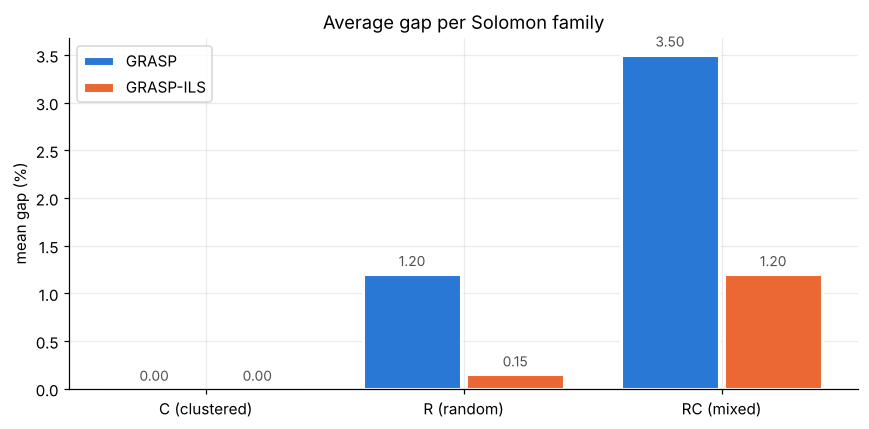

In [18]:
fam = (ok.groupby(["Variant", "Family"])
         .agg(mean_gap=("Gap (%)", "mean"), worst_gap=("Gap (%)", "max"),
              runtime=("Runtime (s)", "mean"), feasible=("Feasible", "mean"))
         .reset_index())
display(fam.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
fams = ["C", "R", "RC"]
for k, (variant, color) in enumerate(VARIANT_COLOR.items()):
    s = fam[fam.Variant == variant].set_index("Family").reindex(fams)
    xs = np.arange(3) + (k - 0.5) * 0.4
    ax.bar(xs, s.mean_gap, 0.38, color=color, label=variant, edgecolor="white", linewidth=2)
    for xi, v in zip(xs, s.mean_gap):
        ax.text(xi, v + 0.05, f"{v:.2f}", ha="center", va="bottom", fontsize=9, color="#52514e")
ax.set_xticks(range(3), ["C (clustered)", "R (random)", "RC (mixed)"])
ax.set_ylabel("mean gap (%)"); ax.set_title("Average gap per Solomon family"); ax.legend()
plt.tight_layout(); plt.show()

Difficulty grows from C to R to RC. In RC the clusters and the scattered customers compete
for the same trucks, so a good solution needs moves that reassign whole groups between routes,
which is exactly what the kicks provide.

### 8.3 Runtime by dataset

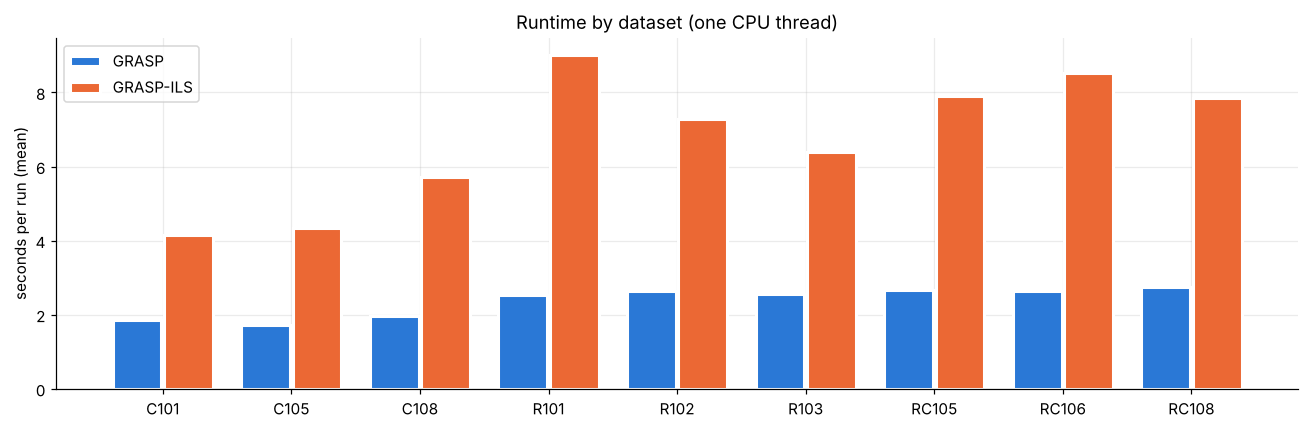

In [19]:
fig, ax = plt.subplots(figsize=(12, 4))
for k, (variant, color) in enumerate(VARIANT_COLOR.items()):
    s = per_inst[per_inst.Variant == variant].set_index("Dataset").loc[order]
    ax.bar(x + (k - 0.5) * 0.4, s.Runtime, 0.38, color=color, label=variant,
           edgecolor="white", linewidth=2)
ax.set_xticks(x, order); ax.set_ylabel("seconds per run (mean)")
ax.set_title("Runtime by dataset (one CPU thread)"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

Plain GRASP needs a few seconds per instance and GRASP-ILS about three times more; both stay
well within an interactive budget for 100 customers.

### 8.4 Stability across seeds

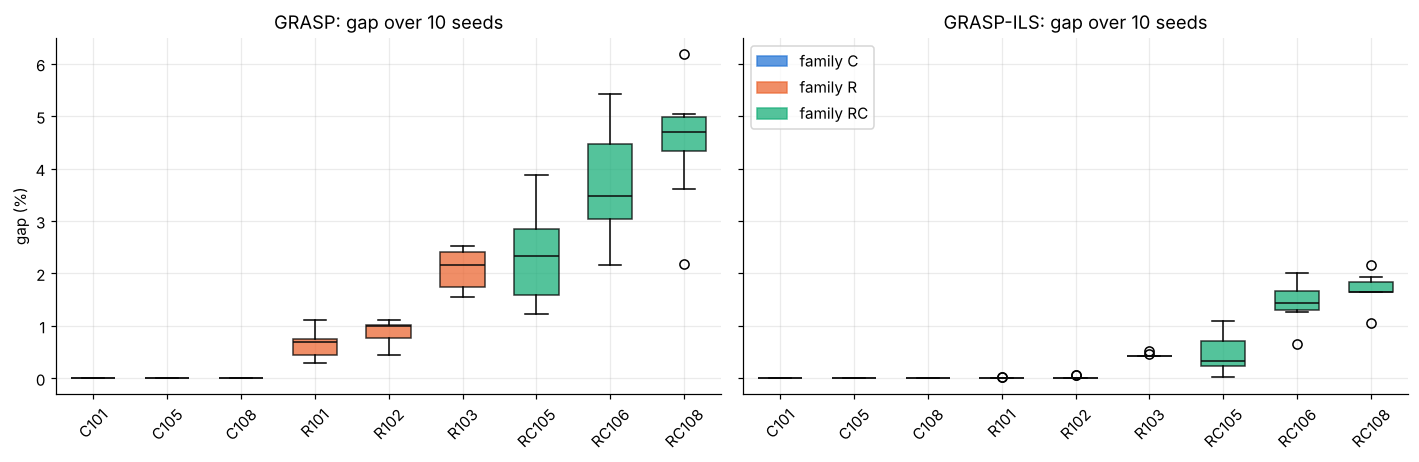

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, variant in zip(axes, VARIANT_COLOR):
    data = [ok[(ok.Variant == variant) & (ok.Dataset == n)]["Gap (%)"].values for n in order]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, medianprops={"color": "#0b0b0b"})
    for patch, n in zip(bp["boxes"], order):
        patch.set_facecolor(FAMILY_COLOR[family(n)]); patch.set_alpha(0.75)
    ax.set_xticks(range(1, len(order) + 1), order, rotation=45)
    ax.set_title(f"{variant}: gap over 10 seeds")
axes[0].set_ylabel("gap (%)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.75) for c in FAMILY_COLOR.values()]
axes[1].legend(handles, [f"family {f}" for f in FAMILY_COLOR], loc="upper left")
plt.tight_layout(); plt.show()

The box height is the seed-to-seed spread. GRASP-ILS is not only better on average, its
boxes are also narrower: the result depends much less on the seed.

### 8.5 Computation time against instance size

,Instance,n,Routes,Feasible,Seconds per iteration
0,X-n101-k25,100,26,True,0.02
1,X-n200-k36,199,37,True,0.07
2,X-n303-k21,302,21,True,0.14
3,X-n401-k29,400,29,True,0.39
4,random-1000,1000,54,True,2.72
5,random-2000,2000,111,True,14.45


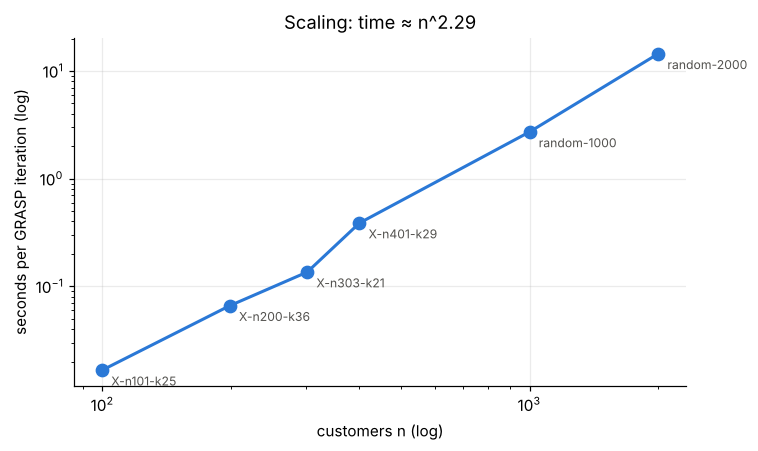

In [21]:
SCALING = [("X-n101-k25", None), ("X-n200-k36", None), ("X-n303-k21", None), ("X-n401-k29", None),
           ("random-1000", 1000), ("random-2000", 2000)]
scale_rows = []
for name, n_rand in SCALING:
    try:
        inst = Instance.random(n_rand, capacity=100, seed=1) if n_rand else load_instance(name)
    except Exception as exc:  # noqa: BLE001
        print(f"{name}: skipped ({exc})"); continue
    r = grasp(inst, GRASPParams(iterations=2), seed=1)
    scale_rows.append({"Instance": name, "n": inst.n_customers, "Routes": len(r.best),
                       "Feasible": r.best.is_feasible(inst),
                       "Seconds per iteration": r.runtime / r.iterations})
scale = pd.DataFrame(scale_rows)
slope, intercept = np.polyfit(np.log(scale.n), np.log(scale["Seconds per iteration"]), 1)
display(scale.round(3))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.loglog(scale.n, scale["Seconds per iteration"], "o-", lw=2, ms=8, color="#2a78d6")
for _, r in scale.iterrows():
    ax.annotate(r.Instance, (r.n, r["Seconds per iteration"]), textcoords="offset points",
                xytext=(6, -10), fontsize=8, color="#52514e")
ax.set_xlabel("customers n (log)"); ax.set_ylabel("seconds per GRASP iteration (log)")
ax.set_title(f"Scaling: time ≈ n^{slope:.2f}")
plt.tight_layout(); plt.show()

The slope of the log-log fit is the empirical complexity of one iteration (construction plus
local search). It stays polynomial and of moderate degree, so instances of several thousand
customers remain solvable in minutes, as the ADEME brief requires.

## 9. Statistical performance analysis

Unit of analysis: the **instance** (as fixed in the team's experimental design). For each
instance and variant, the 10 seeds give a mean, a spread and a 95 % confidence interval
(Student $t$). The two variants are compared with a **Wilcoxon signed-rank test** on the
paired per-instance mean gaps (non-parametric, because gaps are bounded below by 0 and
skewed).

In [22]:
def ci95(values):
    v = np.asarray(values, dtype=float)
    half = stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return half

table = (ok.groupby(["Dataset", "Variant"])["Gap (%)"]
           .agg(mean="mean", std="std", min="min", max="max", ci95=ci95)
           .unstack("Variant"))
table = table.reindex(order)
table.round(2)

mean             std             min             max            ci95  \
Variant GRASP GRASP-ILS GRASP GRASP-ILS GRASP GRASP-ILS GRASP GRASP-ILS GRASP   
Dataset                                                                         
C101     0.00      0.00  0.00      0.00  0.00      0.00  0.00      0.00  0.00   
C105     0.00      0.00  0.00      0.00  0.00      0.00  0.00      0.00  0.00   
C108     0.00      0.00  0.00      0.00  0.00      0.00  0.00      0.00  0.00   
R101     0.64      0.00  0.24      0.01  0.29      0.00  1.11      0.02  0.17   
R102     0.87      0.01  0.24      0.03  0.44      0.00  1.12      0.07  0.17   
R103     2.09      0.44  0.37      0.03  1.56      0.42  2.53      0.51  0.27   
RC105    2.35      0.47  0.88      0.36  1.23      0.03  3.87      1.10  0.63   
RC106    3.66      1.44  1.03      0.38  2.16      0.65  5.43      2.00  0.74   
RC108    4.51      1.70  1.05      0.29  2.17      1.06  6.18      2.16  0.75   

                   
Variant GRASP-ILS  
Dataset            
C101         0.00  
C105         0.00  
C108         0.00  
R101         0.01  
R102         0.02  
R103         0.02  
RC105        0.25  
RC106        0.27  
RC108        0.20

In [23]:
paired = per_inst.pivot(index="Dataset", columns="Variant", values="Gap_mean").reindex(order)
diff = paired["GRASP"] - paired["GRASP-ILS"]
w = stats.wilcoxon(paired["GRASP"], paired["GRASP-ILS"], alternative="greater", zero_method="zsplit")
summary = pd.DataFrame({
    "runs": ok.groupby("Variant").size(),
    "feasible (%)": 100 * ok.groupby("Variant").Feasible.mean(),
    "mean gap (%)": ok.groupby("Variant")["Gap (%)"].mean(),
    "median gap (%)": ok.groupby("Variant")["Gap (%)"].median(),
    "worst gap (%)": ok.groupby("Variant")["Gap (%)"].max(),
    "runs with gap <= 7 %": 100 * ok.groupby("Variant")["Gap (%)"].apply(lambda g: (g <= 7).mean()),
    "mean seed std (pts)": ok.groupby(["Variant", "Dataset"])["Gap (%)"].std().groupby("Variant").mean(),
    "mean runtime (s)": ok.groupby("Variant")["Runtime (s)"].mean(),
})
display(summary.round(2))
print(f"Wilcoxon signed-rank, H1: GRASP gap > GRASP-ILS gap, over {len(paired)} instances: "
      f"W = {w.statistic:.1f}, p = {w.pvalue:.4f}")
print(f"median per-instance improvement: {diff.median():.2f} gap points "
      f"(instances where ILS is better: {(diff > 1e-9).sum()}/{len(diff)}, ties: {(diff.abs() <= 1e-9).sum()})")

,runs,feasible (%),mean gap (%),median gap (%),worst gap (%),runs with gap <= 7 %,mean seed std (pts),mean runtime (s)
Variant,,,,,,,,
GRASP,90,100.0,1.57,1.0,6.18,100.0,0.42,2.37
GRASP-ILS,90,100.0,0.45,0.0,2.16,100.0,0.12,6.80


Wilcoxon signed-rank, H1: GRASP gap > GRASP-ILS gap, over 9 instances: W = 42.0, p = 0.0156
median per-instance improvement: 0.86 gap points (instances where ILS is better: 6/9, ties: 3)


**Reading.** All 180 runs are feasible, and every single run is below the 7 % target (the
worst plain-GRASP run is 6.2 %, the worst GRASP-ILS run 2.2 %). Over the nine test instances,
GRASP-ILS lowers the mean gap from about 1.6 % to about 0.45 %; it is better on the six R and RC
instances and ties on the three C instances, where both variants always find the optimum
(827.3). The Wilcoxon test rejects "no difference" at the 5 % level (p ≈ 0.016, which is the
smallest p-value reachable with six non-tied pairs). The cost is runtime: about 2.4 s per run
for plain GRASP against about 6.8 s for GRASP-ILS. The seed-to-seed standard deviation also
drops (for example RC108: about 1.05 points for GRASP, 0.29 for GRASP-ILS), so the improved
version is also the more reliable one.

*Caveat.* Nine instances is a small sample for a test across instances; the conclusion is
backed mostly by the size and consistency of the differences, not by the p-value alone.

## 10. Conclusions

**What works.**
- On the Solomon instances tested (3 per family), the GRASP produces **feasible solutions in
  100 % of the 180 runs**, checked by the team's shared evaluator, with a mean gap of **1.6 %
  (plain GRASP)** and **0.45 % (GRASP-ILS)** to the distance-optimal values, and no run above
  7 %. C instances are solved to optimality; R101 is reached at 0.00 % by GRASP-ILS.
- Runtime is a few seconds per 100-customer instance in pure Python, thanks to the O(1)
  time-window checks and the granular neighbor lists. One iteration grows as about
  $n^{2.2}$ and still takes only ~14 s at 2 000 customers.
- The same code solves the CVRP: on X-n101-k25 the gap is 2.6 % (GRASP) and 0.7 % (GRASP-ILS).

**What the parameters taught us** (tuning set only).
- **α = 0.1** is best: with time windows, very random starts waste trucks that the local
  search cannot recover.
- **First improvement** gives about the same quality as best improvement at half the time.
- **Regret insertion** and the **cross-exchange** operator each help; a time push-forward
  term in the insertion cost does not.
- At an **equal 10 s budget**, deeper starts (kicks) beat more starts: 0.6 % against 2.4 %.

**Limitations.**
- Difficulty grows from C to R to RC; the remaining gap is concentrated in RC (up to 6 % for
  plain GRASP on RC108).
- The test set has 9 instances because C102, R105, RC101 and RC102 could not be downloaded in
  this environment; adding them to `data/solomon/` makes the notebook include them
  automatically.
- Only the type-1 (short-horizon) Solomon instances are in the test set; wide-window
  instances (C104, R112, RC104, and the type-2 sets) are harder for this local search, as the
  tuning set shows.
- The objective is distance, as in the reference values; it does not minimize the number of
  trucks first, so it sometimes uses one more truck than the hierarchical best known
  solutions.
- The traffic-dependent travel times of the team model (notebook 01) are not used here: the
  VRPLIB and Solomon gaps need the no-traffic mode agreed by the team. The algorithm only reads
  `inst.dist`, so a traffic evaluator can be plugged in later.

**Next steps.**
1. Run the four missing instances and the type-2 instances.
2. Run the same 10-seed campaign with the same time budget for Tabu Search and Simulated
   Annealing, then apply the team's Friedman and Holm tests (notebook 03).
3. Possible improvements: path relinking between elite solutions, an explicit route
   minimization phase, and time-aware neighbor lists for wide windows.

### References
- Feo, T. A., and Resende, M. G. C. (1995). Greedy randomized adaptive search procedures. *Journal of Global Optimization*, 6, 109-133.
- Resende, M. G. C., and Ribeiro, C. C. (2010). Greedy randomized adaptive search procedures: advances, hybridizations, and applications. In *Handbook of Metaheuristics*, Springer.
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254-265.
- Savelsbergh, M. W. P. (1992). The vehicle routing problem with time windows: minimizing route duration. *ORSA Journal on Computing*, 4(2), 146-154.
- Potvin, J.-Y., and Rousseau, J.-M. (1995). An exchange heuristic for routeing problems with time windows. *Journal of the Operational Research Society*, 46, 1433-1446 (2-opt*).
- Taillard, É., Badeau, P., Gendreau, M., Guertin, F., and Potvin, J.-Y. (1997). A tabu search heuristic for the vehicle routing problem with soft time windows. *Transportation Science*, 31(2), 170-186 (cross-exchange).
- Toth, P., and Vigo, D. (2003). The granular tabu search and its application to the vehicle-routing problem. *INFORMS Journal on Computing*, 15(4), 333-346.
- Kohl, N., Desrosiers, J., Madsen, O. B. G., Solomon, M. M., and Soumis, F. (1999). 2-path cuts for the vehicle routing problem with time windows. *Transportation Science*, 33(1), 101-116 (optimal distances).
- Uchoa, E., et al. (2017). New benchmark instances for the capacitated vehicle routing problem. *European Journal of Operational Research*, 257(3), 845-858 (X instances).
- Optimal Solomon distances: S. Spoorendonk's tables, DIKU, University of Copenhagen. Hierarchical best known values: SINTEF TOP, sintef.no/projectweb/top/vrptw.